In [4]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Sample BBO of the oral microbial communities

In [5]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf

In [6]:
Plots.theme(:dao)

In [7]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [8]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [9]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

For each classification, split up on the sample.

In [10]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Index choice below specifies the index of system we are dealing with.

In [121]:
ind_choice = 1;

In [122]:
gd_classes[ind_choice];

In [123]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [124]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

492477.0

Let's choose the smallest of these systems as the initial condition.

In [125]:
argmin(sizes)

439

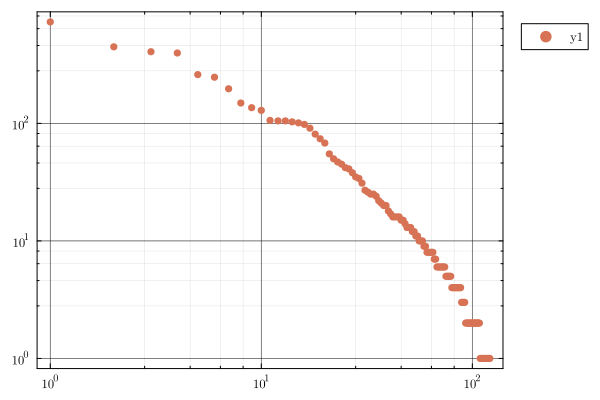

In [126]:
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count],rev=true)
scatter(ic_sys, xaxis = :log, yaxis = :log)

Let's import the calibration results.

In [127]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results/eco-calib-$(ind_choice).csv", DataFrame)

Row,p0,theta,gamma,fitness
,Float64,Float64,Float64,Float64
1,38.7318,0.943649,1.07119,7.3258
2,33.9604,0.874592,0.973496,3.21744
3,34.4576,0.891657,0.956994,5.08784
4,24.7627,0.963591,1.20417,4.45829
5,42.0548,0.919601,0.998161,5.17866
6,43.4224,0.913785,0.976645,6.00489
7,43.1665,0.940562,0.992873,4.63412
8,31.9806,0.911118,0.981139,6.46155
9,43.058,0.97551,1.05465,5.78699


In [128]:
calib_results[1,1]

38.73182191941525

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [196]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 10;
idx = top10i[size_order]

464

In [197]:
guess_sim = dsim.create_cell(calib_results[size_order,2],calib_results[size_order,3],calib_results[size_order,1], convert(Int64,sizes[idx]), ic_sys, :pdf);

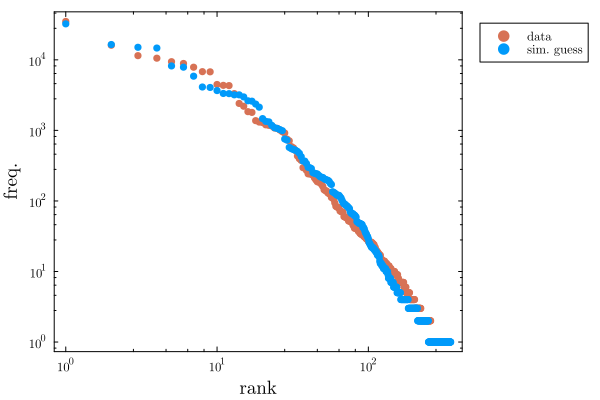

In [198]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

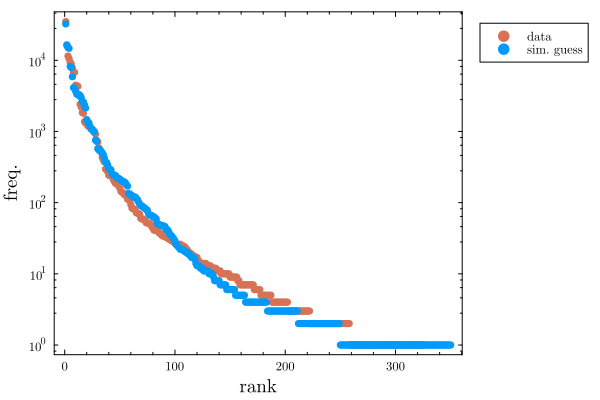

In [199]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

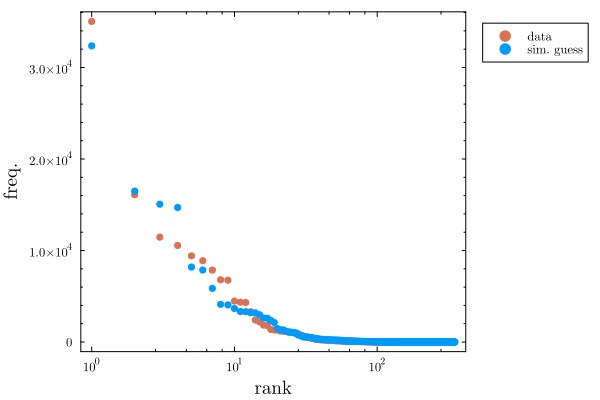

In [200]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

Great results. Pretty quickly, we can get something that is bang on!

In [183]:
logxs = log10.(sum.([x[!,:count] for x in data]))
logys = log10.(length.([x[!,:count] for x in data]));

In [184]:
df = DataFrame(y = logys, x = logxs);

In [185]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.661884   0.127708    5.18    <1e-06   0.410939   0.912828
x            0.354613   0.0260115  13.63    <1e-35   0.303501   0.405726
────────────────────────────────────────────────────────────────────────

In [186]:
a,b = coef(glm)

2-element Vector{Float64}:
 0.6618836043834962
 0.3546134703391564

Following the SI of the PNAS paper...

In [187]:
θ = 2+1/(b-1);

In [188]:
ic_sys;

In [204]:
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)))
p0_guess = α*a*b

0.4377575561520065

In [190]:
la_sys = vcat(data[argmax(sizes)][!,:count])
α = sum([k^θ for k in la_sys])/(sum(la_sys)^(1/(2-θ)))
p0_guess = α*a*b

0.15722848117141797

Modified calculation of $\alpha$ where the difference between max and min is taken into account.

In [202]:
la_sys = vcat(data[argmax(sizes)][!,:count])
α = (sum([k^θ for k in la_sys]) - sum([k^θ for k in ic_sys]))/(sum(la_sys)^(1/(2-θ)) - sum(ic_sys)^(1/(2-θ)))
p0_guess = α*a*b

0.14162402050820858

In [155]:
data[argmax(sizes)][!,:count]

398-element view(::Vector{Float64}, [97647, 97648, 97649, 97650, 97651, 97652, 97653, 97654, 97655, 97656  …  98035, 98036, 98037, 98038, 98039, 98040, 98041, 98042, 98043, 98044]) with eltype Float64:
    18.0
  5026.0
     1.0
     4.0
     1.0
    80.0
   202.0
     1.0
 10832.0
     2.0
    12.0
     4.0
     5.0
     ⋮
     1.0
     1.0
     3.0
    22.0
     1.0
     1.0
     1.0
     1.0
  2111.0
   108.0
    98.0
   270.0